In [1]:
import functools
import os
import json

from ultralytics import YOLO
import pandas as pd

import ultralytics_validator_wrapper
from tflite_inference import TFLiteInferer

pd.options.display.float_format = '{:.3f}'.format

%matplotlib inline
%load_ext autoreload
%autoreload 2

TensorFlow version:  2.17.0


In [2]:
BASE_EXPERIMENT_DIR = "results/filtered_v3_margin_15_reduced_quality"
WEIGHTS_PTH = os.path.join(BASE_EXPERIMENT_DIR, "weights/best.pt")

BASE_PTH = "/home/klymy/data/people_detection/filtered_v3_margin_15_reduced_quality"

VAL_PTH = os.path.join(BASE_PTH, "project.yaml")
HOLDOUT_PTH = os.path.join(BASE_PTH, "project_holdout.yaml")
ALGOTEST_PTH = os.path.join(BASE_PTH, "project_algotest.yaml")

# CONF_TH = 0.25
# IOU_TH = 0.55
if os.path.exists(os.path.join(BASE_EXPERIMENT_DIR, "inference_params.json")):
    with open(os.path.join(BASE_EXPERIMENT_DIR, "inference_params.json"), "r") as f:
        data = json.load(f)
    CONF_TH = float(data["conf_th"])
    IOU_TH = float(data["iou_th"])
else:
    print("No inference_params.json found, using default thresholds.")
    CONF_TH = 0.35
    IOU_TH = 0.50

args = dict(
    data=ALGOTEST_PTH,
    task="pose",
    device=[0],
    batch=128,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
    imgsz=320,
    model="val",
    rect=False,
    single_cls=False,
)

No inference_params.json found, using default thresholds.


In [3]:
model = YOLO(WEIGHTS_PTH)

val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15_reduced_quality/labels/algotest.cache... 9572 images, 559 backgrounds, 0 corrupt: 100%|██████████| 9572/9572 [00:00<?, ?it/s]
tst validation: 100%|██████████| 75/75 [01:08<00:00,  1.09it/s]


                   all       9572      51930      0.906      0.883      0.913      0.604      0.915      0.899      0.928      0.924
   task    F1     P     R  MAP@50
0   box 0.895 0.906 0.883   0.913
1  pose 0.907 0.915 0.899   0.928


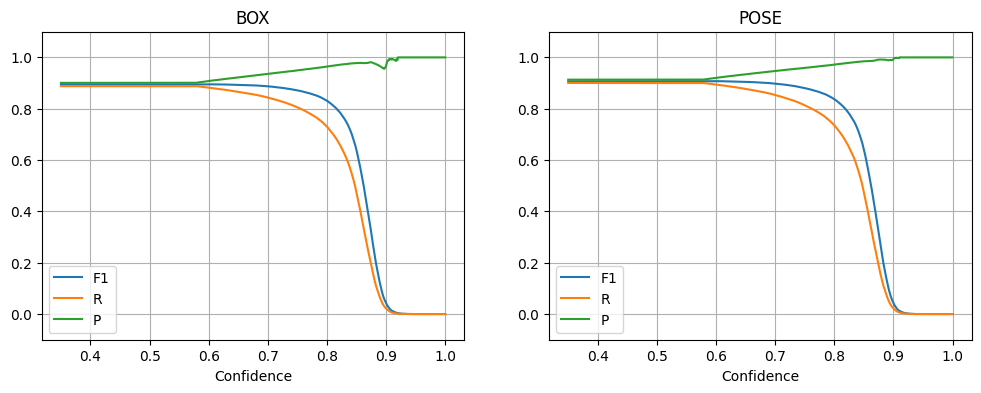

In [4]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_ultralytics, model, args),
)

In [5]:
inferer = TFLiteInferer(
    yolo_pth="results/filtered_v3_margin_15/weights/best_saved_model/best_full_integer_quant.tflite",
    head_pth="results/filtered_v3_margin_15/weights/head_saved_model/head_float32.tflite",
    conf_th=CONF_TH,
    iou_th=IOU_TH,
    imgsz=320,
)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15_reduced_quality/labels/algotest.cache... 9572 images, 559 backgrounds, 0 corrupt: 100%|██████████| 9572/9572 [00:00<?, ?it/s]
tst validation: 100%|██████████| 75/75 [06:08<00:00,  4.91s/it]


                   all       9572      51930      0.883      0.718      0.807      0.489      0.921      0.749      0.843      0.838
   task    F1     P     R  MAP@50
0   box 0.792 0.883 0.718   0.807
1  pose 0.826 0.921 0.749   0.843


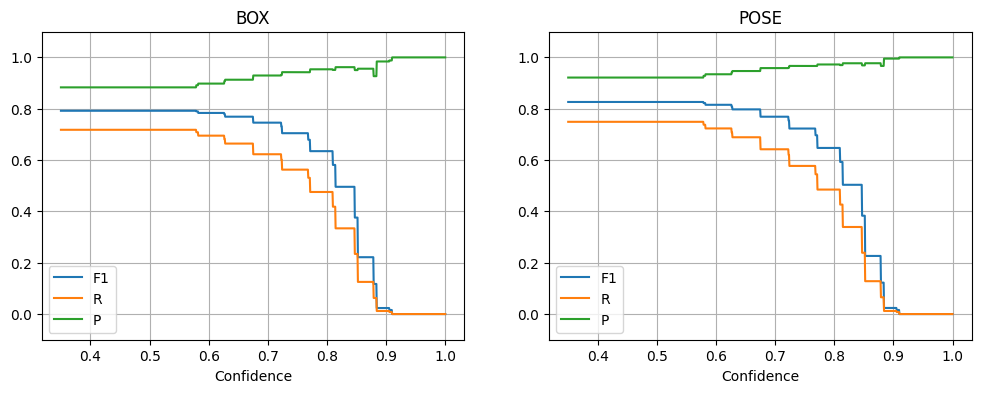

In [6]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args)
)

In [7]:
args["data"] = HOLDOUT_PTH

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_ultralytics, model, args),
    False,
)

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args),
    False,
)

val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15_reduced_quality/labels/holdout.cache... 22049 images, 556 backgrounds, 0 corrupt: 100%|██████████| 22049/22049 [00:00<?, ?it/s]
tst validation: 100%|██████████| 173/173 [02:43<00:00,  1.06it/s]


                   all      22049     114004      0.913      0.899      0.929      0.635      0.928      0.919      0.947      0.944
   task    F1     P     R  MAP@50
0   box 0.906 0.913 0.899   0.929
1  pose 0.923 0.928 0.919   0.947


val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15_reduced_quality/labels/holdout.cache... 22049 images, 556 backgrounds, 0 corrupt: 100%|██████████| 22049/22049 [00:00<?, ?it/s]
tst validation: 100%|██████████| 173/173 [14:11<00:00,  4.92s/it]


                   all      22049     114004      0.878      0.727      0.818       0.49      0.928      0.768      0.862      0.858
   task    F1     P     R  MAP@50
0   box 0.795 0.878 0.727   0.818
1  pose 0.841 0.928 0.768   0.862
